<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DEEP-LEARINING-/blob/main/Experiment_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MAE: 5.102681068210403 RMSE: 6.703837608239062


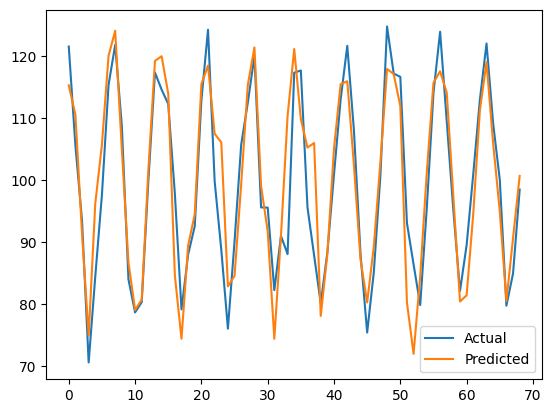

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
rng=np.random.default_rng(13); series=100+20*np.sin(np.arange(365)*2*np.pi/7)+rng.normal(0,5,365)
s=MinMaxScaler(); z=s.fit_transform(series[:,None])
X=np.array([z[i:i+24] for i in range(len(z)-24)]); y=z[24:]
split=int(len(X)*.8); Xt,Xv=X[:split],X[split:]; yt,yv=y[:split],y[split:]
m=tf.keras.Sequential([tf.keras.layers.Input((24,1)),tf.keras.layers.SimpleRNN(32),tf.keras.layers.Dense(1)]); m.compile('adam','mse'); m.fit(Xt,yt,epochs=10,verbose=0)
p=s.inverse_transform(m.predict(Xv,verbose=0)); actual=s.inverse_transform(yv); print('MAE:',np.mean(abs(p-actual)),'RMSE:',np.sqrt(np.mean((p-actual)**2)))
plt.plot(actual); plt.plot(p); plt.legend(['Actual','Predicted']); plt.show()